# Разработка модели поведенческого скоринга

## Подготовка рабочего пространства

* Дайте этой тетрадке Jupyter название, которое корректно отражает суть проекта.
* Опишите постановку задачи своими словами, коротко зафиксировав основной смысл.
* Опишите данные, которые даны для решения задачи.

Необходимо построить модель поведенческого скоринга, которая по данным о клиенте в выбранный месяц прогнозирует, возникнет ли у него просрочка на 90 дней или более.​

## Перевод бизнес-задачи на язык машинного обучения

* Напишите, что конкретно будете делать, пользуясь терминами машинного обучения:
  * какие модели будете использовать;
  * какие методы работы с данными применять;
  * как планируете решать поставленную задачу.


- загрузим датасеты;
- проведем первичный анализ;
- собирем витрину;
- проведем EDA витрины;
- разделим данные на тренировочные, калибровочную и тестовые;
- обучим базовые варианты нескольких моделей с кросс-валидацией на трёх фолдах: логистическую регрессию и случайный лес, используя метод балансировки классов;
- выберем лучую модель, обучим ее на всей тренировочной выборке;
- сверим с пороговыми значениями метрик: 
    - Approval rate не менее 65%.
    - Default rate не более 2%.
    - Missed defaults rate не более 4%.
- Зафиксируем итоговые параметры лучшей модели.

## Загрузка необходимых библиотек

* Загрузите все библиотеки, необходимые для выполнения проекта.

In [1]:
%pip install -q numpy==2.3.5

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [64]:
import pandas as pd
import numpy as np

import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib import get_data_path 

from pathlib import Path
from data_profiling import ProfileReport
import optuna

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, accuracy_score, confusion_matrix
from sklearn.calibration import CalibratedClassifierCV
from sklearn.metrics import brier_score_loss

from imblearn.pipeline import Pipeline as ImbPipeline 
from imblearn.over_sampling import RandomOverSampler
from imblearn.under_sampling import RandomUnderSampler



from mlxtend.evaluate.time_series import (
    GroupTimeSeriesSplit,
    plot_splits,
    print_cv_info,
    print_split_info,
) 

In [3]:
RANDOM_STATE = 42

## Загрузка данных

* Загрузите предоставленные датасеты. Обратите внимание на то, как загрузятся данные, в каком формате представлены таблицы. Пути к данным:
  * `'/datasets/ds_15_loan_payment_credit.csv'`;
  * `'/datasets/ds_15_transactions.csv'`;
  * `'/datasets/ds_15_client_description.csv'`;
  * `'/datasets/ds_15_credit_description.csv'`;
  * `'/datasets/ds_15_mortgage_presence.csv'`;
  * `'/datasets/ds_15_credit_rating.csv'`;
  * `'/datasets/ds_15_macro_data.csv'`;
  * `'/datasets/ds_15_cohort_grid.csv'`.
* Посмотрите на содержимое таблиц. Сделайте первые выводы о них.

In [4]:
load_payment_credit = pd.read_csv('datasets\ds_15_loan_payment_credit.csv')
transactions = pd.read_csv('datasets/ds_15_transactions.csv')
client_description = pd.read_csv('datasets/ds_15_client_description.csv')
credit_description = pd.read_csv('datasets/ds_15_credit_description.csv')
mortgage_presence = pd.read_csv('datasets/ds_15_mortgage_presence.csv')
credit_rating = pd.read_csv('datasets/ds_15_credit_rating.csv')
macro_data = pd.read_csv('datasets/ds_15_macro_data.csv')
cohort_grid = pd.read_csv('datasets/ds_15_cohort_grid.csv')

<>:1: SyntaxWarning: invalid escape sequence '\d'
<>:1: SyntaxWarning: invalid escape sequence '\d'
C:\Users\kryto\AppData\Local\Temp\ipykernel_11372\3826003133.py:1: SyntaxWarning: invalid escape sequence '\d'
  load_payment_credit = pd.read_csv('datasets\ds_15_loan_payment_credit.csv')


## Исследовательский анализ данных

* Проведите первичный анализ данных:
    * Проверьте разные характеристики данных.
    * Исследуйте с помощью графиков количественные и категориальные данные.
    * Рекомендуем создать для этого функции, но это необязательное требование.

* Сделайте выводы о выбросах, пропусках, дубликатах и иных аномалиях в данных из каждой таблицы.

* Предобработка данных или их трансформация в этом проекте необязательны — кроме действий, необходимых для объединения таблиц.

Создадим функцию для быстрого анализа таблиц

In [5]:
def start_analyze(df):

    df.info()
    print('--'*30)
    print(df.describe(include='all'))
    print('--'*30)
    print(f'Дубликатов всего: {df.duplicated().sum()}')
    print(f'Пропусков всего: {df.isna().sum().sum()}')
    print('--'*30)    
    print(df.head(3))
    print('--'*30)
    print(df.tail(3))
    num_col = df.select_dtypes(include='number').columns
    if name != 'cohort_grid':
        df[num_col].hist()



In [6]:
tables = {
    'load_payment_credit':  load_payment_credit,
    'transactions':         transactions,
    'client_description':   client_description,
    'credit_description':   credit_description,
    'mortgage_presence':    mortgage_presence,
    'credit_rating':        credit_rating,
    'macro_data':           macro_data,
    'cohort_grid':          cohort_grid,
}

АНАЛИЗ ТАБЛИЦЫ load_payment_credit

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5500 entries, 0 to 5499
Data columns (total 3 columns):
 #   Column               Non-Null Count  Dtype 
---  ------               --------------  ----- 
 0   ID                   5500 non-null   object
 1   дата_начала_периода  5500 non-null   object
 2   просрочка_дней       5500 non-null   int64 
dtypes: int64(1), object(2)
memory usage: 129.0+ KB
------------------------------------------------------------
                 ID дата_начала_периода  просрочка_дней
count          5500                5500     5500.000000
unique         5500                  73             NaN
top     IDF55109846          2018-12-01             NaN
freq              1                 209             NaN
mean            NaN                 NaN      114.748000
std             NaN                 NaN       20.362422
min             NaN                 NaN       80.000000
25%             NaN                 NaN       97.000

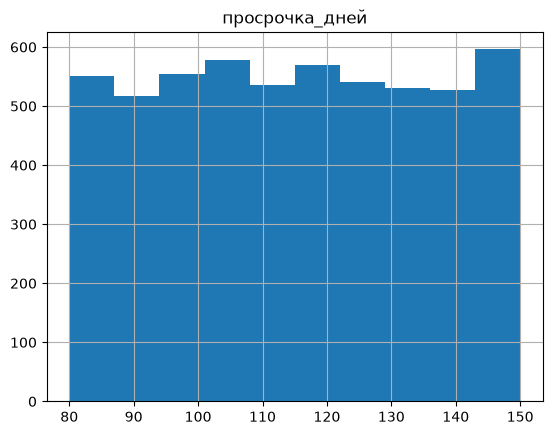

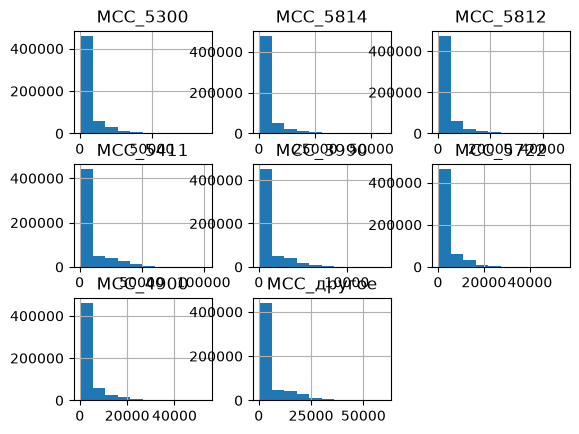

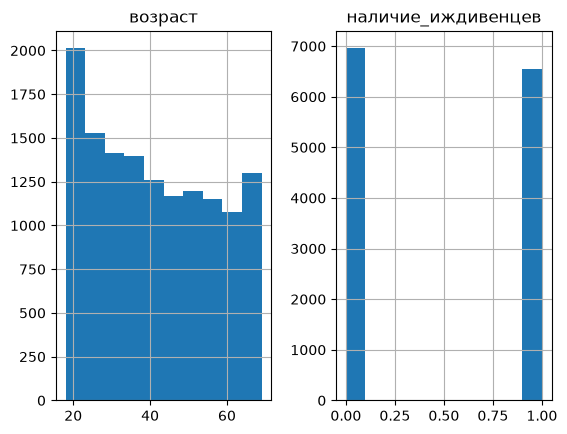

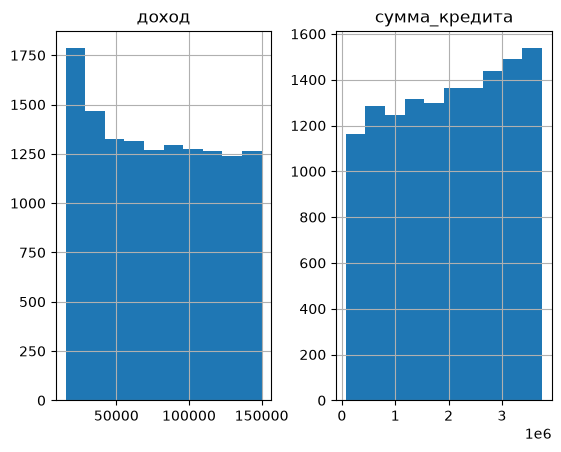

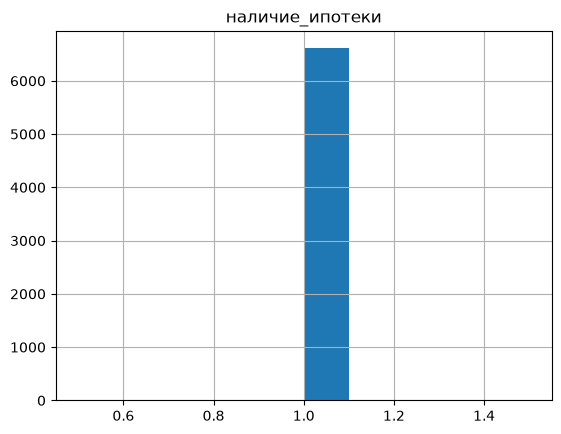

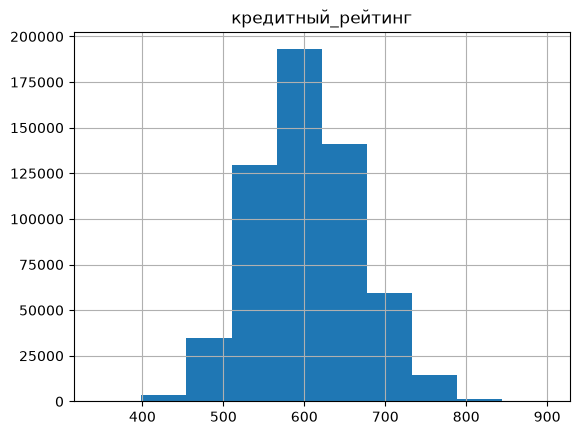

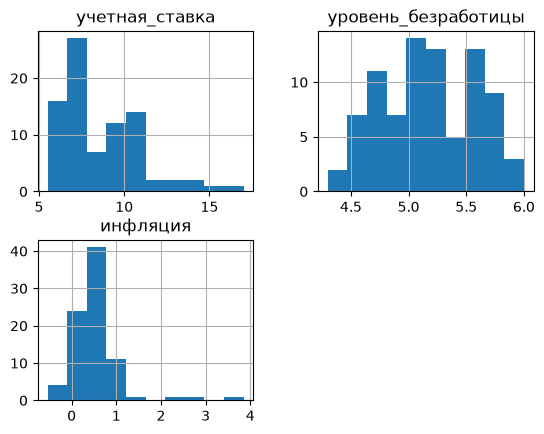

In [7]:
for name, df in tables.items():
    print('='*30)
    print(f'АНАЛИЗ ТАБЛИЦЫ {name}')
    print()
    start_analyze(df)
    print()

По результатам предварительного анализа можно сделать следующие выводы:
-  load_payment_credit:
	- пропусков и дубликатов нет;
	- надо будет привести столбец "дата_начала_периода" к типу date и, возможно, поменять название;
	-  в столбце "просрочка_дней" значения равномерно распределены
-  transactions: 
	- пропусков и дубликатов нет;
	- надо будет привести столбец "date" к типу date;
	- все столбцы "MCC" имеют явный правый хвост;
- client_description:
	- пропусков и дубликатов нет;
	- "дата_регистрации", если будем ее использовать, надо будет привести к типу date
	-  в столбце "возраст" преобладают молодые, иждевенцы  
- credit_description
	- пропусков и дубликатов нет;
	- "Доход" и "сумма кредита" распределены плюс минус равномерно, хотя прослеживается, что низкого дохода меньше, чем высокого, а сумма кредита - наоборот
- mortgage_presence
	- пропусков и дубликатов нет;
	- у всех клиентов есть ипотека;
- credit_rating
	- пропусков и дубликатов нет;
	- надо будет привести столбец "date" к типу date;
	- кредитный рейтинг показывает идеальное нормальное распределение
- macro_data
	- пропусков и дубликатов нет;
	- учетная ставка скачет,
	- уровень безработицы распределен почти нормально, но в районе 5,5 наблюдается снижение
	- инфляция находится в районе 0-1, но с правым хвостом
- cohort_grid
	- пропусков и дубликатов нет;
	- надо будет привести столбец "score_date" к типу date;


Преобразуем Дату в тип Date

In [8]:
load_payment_credit['дата_начала_периода'] = pd.to_datetime(load_payment_credit['дата_начала_периода'])
transactions['date'] = pd.to_datetime(transactions['date'])
client_description['дата_регистрации'] = pd.to_datetime(client_description['дата_регистрации'])
mortgage_presence['дата_открытия'] = pd.to_datetime(mortgage_presence['дата_открытия'])
credit_rating['date'] = pd.to_datetime(credit_rating['date'])
macro_data['date'] = pd.to_datetime(macro_data['date'])
cohort_grid['score_date'] = pd.to_datetime(cohort_grid['score_date'])

## Объединение таблиц

Соберите все источники данных о клиентах в единую таблицу наблюдений.

### Формирование целевой переменной

1. Значение бинарной целевой переменной нужно определить для каждой строки со столбцами `ID` и `score_date` в таблице `cohort_grid`.

2. Таргет равен 1 при соблюдении двух условий:
    * Если значение в поле `просрочка_дней` больше или равно 90.
    * Если для клиента существует строка в таблице `loan_payment_credit`, где значение в поле `дата_начала_периода` попадает в интервал `[score_date, score_date + 365 дней)`.

>Важно: у клиента может быть несколько эпизодов с просрочками от 90 дней. Вам нужно взять первый по времени возникновения эпизод в таблице с просрочками.

3. После расчёта целевой переменной удалите строки, где дефолт уже произошёл к моменту скоринга, то есть `дата_начала_периода < score_date`. Это необходимо, так как для корректной работы с временной структурой важно учитывать дефолты, произошедшие в прошлом относительно даты скоринга.

### Создание итоговой таблицы

1. В качестве признаков можно использовать только информацию о прошлом, то есть она должна быть доступна к дате скоринга. Иными словами, в каждой строке нужно присоединить данные о поведении клиента за предыдущие периоды относительно даты скоринга, иначе произойдёт утечка данных из будущего.

>К примеру, `score_date = 2024-01-15`. Тогда:
>* транзакции за декабрь 2023 г. — можем использовать;
>* транзакции за ноябрь 2023 г. — можем использовать;
>* транзакции 16 января 2024 г. — **не** можем использовать.

2. Присоедините остальные данные по клиенту, помимо указанных выше данных о макроэкономике и транзакциях клиента.

> Рекомендации:
>* Не забывайте проверять правильность каждого этапа сбора данных в единую таблицу. Это можно отслеживать на одном из клиентов.
>* При формировании таблицы следите за тем, чтобы в ней была корректно проведена работа со временем:
  >   * Отследите, не упущены ли какие-то данные из прошлого;
  >   * Проконтролируйте, верно ли рассчитана целевая переменная, которая зависит от дефолта в будущем.
>* Помните, что даты в исходных таблицах указаны на первое число месяца. Учитывайте период, который они описывают.

Сделайте выводы о получившейся таблице.

Для начала проверим еще раз таблицу cohort_grid

In [9]:
print('Размер:', cohort_grid.shape)
print('Уникальных клиентов:', cohort_grid['ID'].nunique())

print(
    'Дубликатов ID + score_date:',
    cohort_grid.duplicated(['ID', 'score_date']).sum()
)

print('Первая дата:', cohort_grid['score_date'].min())
print('Последняя дата:', cohort_grid['score_date'].max())

Размер: (577494, 2)
Уникальных клиентов: 13500
Дубликатов ID + score_date: 0
Первая дата: 2013-01-01 00:00:00
Последняя дата: 2019-12-01 00:00:00


Попробуем предворительно соединить таблицы transactions и credit_rating с cohort_grid, посмотреть как они будут объединяться.

In [10]:
transactions_keys = (
    transactions[['ID', 'date']]
    .rename(columns={'date': 'score_date'})
)

check_transactions = cohort_grid[['ID', 'score_date']].merge(
    transactions_keys,
    on=['ID', 'score_date'],
    how='outer',
    indicator=True
)

print(check_transactions['_merge'].value_counts())

_merge
both          577494
left_only          0
right_only         0
Name: count, dtype: int64


In [11]:
credit_rating_keys = (
    credit_rating[['ID', 'date']]
    .rename(columns={'date': 'score_date'})
)

check_credit_rating = cohort_grid[['ID', 'score_date']].merge(
    credit_rating_keys,
    on=['ID', 'score_date'],
    how='outer',
    indicator=True
)

print(check_credit_rating['_merge'].value_counts())

_merge
both          577494
left_only          0
right_only         0
Name: count, dtype: int64


Пары значений ID и data уникальны. Теперь посмотрим дату открытия ипотеки относительно даты скоринга

In [12]:

mortgage_check = cohort_grid.merge(
    mortgage_presence,
    on='ID',
    how='left',
    indicator=True
)

print(mortgage_check['_merge'].value_counts())


_merge
left_only     296761
both          280733
right_only         0
Name: count, dtype: int64


Узнаем, есть ли случаи, когда взяли ипотеку до скоринга

In [13]:
print('Дата открытия отсутствует:')
print(mortgage_check['дата_открытия'].isna().sum())

print('\nДата открытия позже даты скоринга:')
print(
    (
        mortgage_check['дата_открытия'].notna()
        & (mortgage_check['дата_открытия'] > mortgage_check['score_date'])
    ).sum()
)

Дата открытия отсутствует:
296761

Дата открытия позже даты скоринга:
0


Таких ситуаций нет, но есть клиенты, которые не брали ипотеку

In [14]:
final_df = cohort_grid.merge(
    load_payment_credit,
    on=['ID'],
    how='left')
final_df = final_df.merge(
    transactions,
    left_on=['ID', 'score_date'],
    right_on=['ID', 'date'],
    how='left')
final_df = final_df.merge(
    client_description,
    on=['ID'],
    how='left')
final_df = final_df.merge(
    credit_description,
    on=['ID'],
    how='left')
final_df = final_df.merge(
    mortgage_presence,
    on=['ID'],
    how='left')
final_df = final_df.merge(
    credit_rating,
    left_on=['ID', 'score_date'],
    right_on=['ID', 'date'],
    how='left')
final_df = final_df.merge(
    macro_data,
    left_on=['score_date'],
    right_on=['date'],
    how='left')



Проверим как объединилась таблица

In [15]:
final_df.head()

,ID,score_date,дата_начала_периода,просрочка_дней,date_x,MCC_5300,MCC_5814,MCC_5812,MCC_5411,MCC_3990,...,доход,сумма_кредита,дата_открытия,наличие_ипотеки,date_y,кредитный_рейтинг,date,учетная_ставка,уровень_безработицы,инфляция
0,IDF55109846,2013-05-01,2014-12-01,120.0,2013-05-01,3267.59,1282.11,1457.96,5711.10,647.43,...,27035,1960785,NaT,NaN,2013-05-01,692,2013-05-01,5.5,5.4,0.66
1,IDF55109846,2013-06-01,2014-12-01,120.0,2013-06-01,3196.58,2443.37,1334.20,5824.65,1067.55,...,27035,1960785,NaT,NaN,2013-06-01,688,2013-06-01,5.5,5.3,0.42
2,IDF55109846,2013-07-01,2014-12-01,120.0,2013-07-01,3550.54,4277.72,1463.75,5209.51,1167.95,...,27035,1960785,NaT,NaN,2013-07-01,666,2013-07-01,5.5,5.3,0.82
3,IDF55109846,2013-08-01,2014-12-01,120.0,2013-08-01,3385.98,4530.63,1261.40,5765.96,986.99,...,27035,1960785,NaT,NaN,2013-08-01,692,2013-08-01,5.5,5.2,0.14
4,IDF55109846,2013-09-01,2014-12-01,120.0,2013-09-01,3214.84,4146.65,1405.15,5632.11,640.76,...,27035,1960785,NaT,NaN,2013-09-01,688,2013-09-01,5.5,5.1,0.21


In [16]:
final_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 577494 entries, 0 to 577493
Data columns (total 27 columns):
 #   Column               Non-Null Count   Dtype         
---  ------               --------------   -----         
 0   ID                   577494 non-null  object        
 1   score_date           577494 non-null  datetime64[ns]
 2   дата_начала_периода  234907 non-null  datetime64[ns]
 3   просрочка_дней       234907 non-null  float64       
 4   date_x               577494 non-null  datetime64[ns]
 5   MCC_5300             577494 non-null  float64       
 6   MCC_5814             577494 non-null  float64       
 7   MCC_5812             577494 non-null  float64       
 8   MCC_5411             577494 non-null  float64       
 9   MCC_3990             577494 non-null  float64       
 10  MCC_5722             577494 non-null  float64       
 11  MCC_4900             577494 non-null  float64       
 12  MCC_другое           577494 non-null  float64       
 13  возраст       

In [17]:
final_df['test'] = (final_df['date'] == final_df['date_x']) & (final_df['date'] == final_df['date_y']) & (final_df['score_date'] == final_df['date_y'])
sum(final_df['test'] == False)

0

Все даты одинаковы, можно удалить столбцы data, data_x, data_y. 

Создадим столбец target

In [18]:
final_df['target'] =(
    (final_df['просрочка_дней'] >= 90)
    &((final_df['дата_начала_периода'] + pd.DateOffset(days=90)).dt.to_period('M') > final_df['score_date'].dt.to_period('M')) 
    &((final_df['дата_начала_периода'] + pd.DateOffset(days=90)).dt.to_period('M') <= (final_df['score_date'] + pd.DateOffset(months=12)).dt.to_period('M'))
).astype('int')

In [19]:
final_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 577494 entries, 0 to 577493
Data columns (total 29 columns):
 #   Column               Non-Null Count   Dtype         
---  ------               --------------   -----         
 0   ID                   577494 non-null  object        
 1   score_date           577494 non-null  datetime64[ns]
 2   дата_начала_периода  234907 non-null  datetime64[ns]
 3   просрочка_дней       234907 non-null  float64       
 4   date_x               577494 non-null  datetime64[ns]
 5   MCC_5300             577494 non-null  float64       
 6   MCC_5814             577494 non-null  float64       
 7   MCC_5812             577494 non-null  float64       
 8   MCC_5411             577494 non-null  float64       
 9   MCC_3990             577494 non-null  float64       
 10  MCC_5722             577494 non-null  float64       
 11  MCC_4900             577494 non-null  float64       
 12  MCC_другое           577494 non-null  float64       
 13  возраст       

Обработаем таблицу. Переработаем столбец с наличием ипотеки, удалим ненужные столбцы. ID пока оставим в таблице, но как признак использовать его не будем.

In [20]:
final_df['наличие_ипотеки'] = (
    final_df['дата_открытия'].notna()
    & (final_df['дата_открытия'] <= final_df['score_date'])
).astype('int')

In [21]:
cols_to_drop = [
    'date_x',
    'date_y',
    'date',
    'дата_начала_периода',
    'просрочка_дней',
    'дата_открытия',
    'test'
]

final_df = final_df.drop(columns=cols_to_drop)

In [22]:
final_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 577494 entries, 0 to 577493
Data columns (total 22 columns):
 #   Column               Non-Null Count   Dtype         
---  ------               --------------   -----         
 0   ID                   577494 non-null  object        
 1   score_date           577494 non-null  datetime64[ns]
 2   MCC_5300             577494 non-null  float64       
 3   MCC_5814             577494 non-null  float64       
 4   MCC_5812             577494 non-null  float64       
 5   MCC_5411             577494 non-null  float64       
 6   MCC_3990             577494 non-null  float64       
 7   MCC_5722             577494 non-null  float64       
 8   MCC_4900             577494 non-null  float64       
 9   MCC_другое           577494 non-null  float64       
 10  возраст              577494 non-null  int64         
 11  семейное_положение   577494 non-null  object        
 12  наличие_иждивенцев   577494 non-null  int64         
 13  дата_регистрац

In [23]:
final_df['семейное_положение'].unique()

array(['разведённые', 'нет семьи', 'есть семья'], dtype=object)

В дальнейшем надо будет обработать с помощью OneHotEncoder

## Создание новых признаков

* Добавьте в таблицу новые признаки, которые помогли бы описать поведение клиента. Создайте не менее двух новых признаков.
* Сделайте выводы о новых признаках.

In [24]:
final_df_new = final_df.sort_values(
    ['ID', 'score_date']
).copy()

final_df_new['MCC_total'] = final_df_new['MCC_5300'] + final_df_new['MCC_5814'] + final_df_new['MCC_5812'] + final_df_new['MCC_5411'] + final_df_new['MCC_3990'] + final_df_new['MCC_5722'] + final_df_new['MCC_4900'] + final_df_new['MCC_другое']

final_df_new['MCC_3_month_mean'] = (
    final_df_new.groupby('ID')['MCC_total']
    .transform(
        lambda s: s.shift(1)
        .rolling(window=3, min_periods=1)
        .mean()
    )
)


Создали 2 новых признака - `MCC_total` - общая сумма трат пользователя за месяц; `MCC_3_month_mean` - скользящее окно, которое показывает среднюю сумму трат пользователя за 3 месяца.

In [25]:
final_df_new[['MCC_total', 'MCC_3_month_mean']].describe()

,MCC_total,MCC_3_month_mean
count,577494.000000,563994.000000
mean,35771.705692,37679.655680
std,46744.238127,45541.959306
min,1190.350000,1432.183333
25%,8391.992500,9260.516667
50%,16023.570000,17428.821667
75%,34938.170000,47054.064167
max,309029.080000,261654.790000


<Axes: >

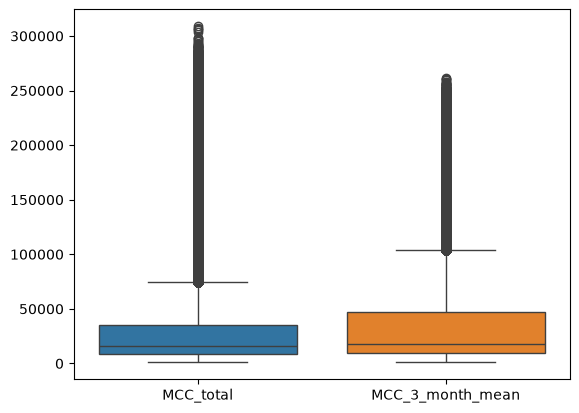

In [26]:
sns.boxplot(data=final_df_new[['MCC_total', 'MCC_3_month_mean']])

<Axes: ylabel='Count'>

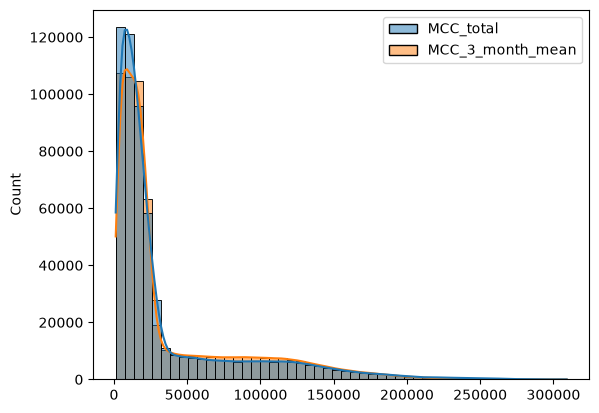

In [27]:
sns.histplot(data=final_df_new[['MCC_total', 'MCC_3_month_mean']], bins=50, kde=True)

По цифрам признак выглядит вполне правдоподобно. Видно, что скользящее среднее сглаживает колебания. Cтандартное отклонение и максимум уменьшились. Cреднее и медиана скользящего среднего выше. Пропуски встречаются из-за того, что нет "истории", заменим их потом медианным значением.

## Анализ итоговой таблицы

* Проведите краткий анализ получившейся итоговой таблицы.
* Сделайте вывод о данных для моделирования.
* Проверьте целевую переменную на предмет дисбаланса классов. Сделайте выводы.

In [28]:

profile = ProfileReport(
    final_df_new,
    explorative=True)

profile.to_notebook_iframe()

Summarize dataset:   0%|          | 0/5 [00:00<?, ?it/s]

100%|██████████| 24/24 [00:07<00:00,  3.35it/s]


Generate report structure:   0%|          | 0/1 [00:00<?, ?it/s]

Render HTML:   0%|          | 0/1 [00:00<?, ?it/s]

<Axes: xlabel='year', ylabel='count'>

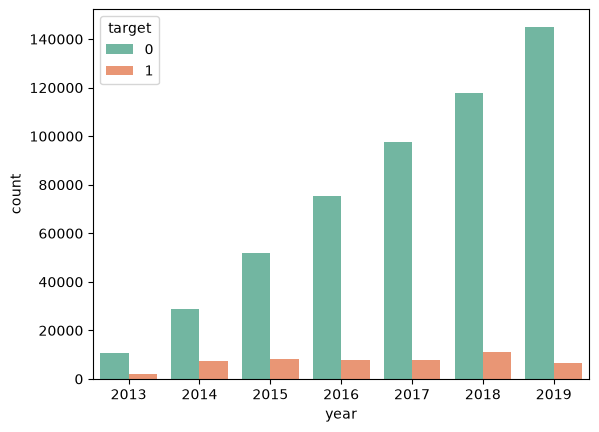

In [29]:
final_df_new['year'] = final_df_new['score_date'].dt.year
sns.countplot(data=final_df_new, x='year', hue='target', palette='Set2')

Витрина данных сохранила почти все характеристики из первоначального анализа.

Пропуски есть только в скользящем окне, это объясняется особенностью метода.

Выбросы наблюдаются в MCC столбцах, доходе, сумма_кредита. Но они выглядят "натурально", т.е. были клиенты, которые много тратят или взяли большую сумму кредита.

В целевой переменной наблюдается явный дисбаланс классов: ~9% на 91%.

## Моделирование

### Базовые модели

1. Подготовьте обучающую, калибровочную и тестовую выборки. Разбейте обучающую на три фолда для последующего использования кросс-валидации. Для оценки качества и калибровки используйте размер выборки, равный 12 месяцам.


2. При необходимости проведите категоризацию данных, применив нужный Encoder и использовав пайплайн.

3. Обучите базовые модели с кросс-валидацией по трём фолдам:
    * Две базовые модели — логистическую регрессию и случайный лес — без балансировки классов в целевой переменной.
    * Логистическую регрессию и случайный лес с балансировкой классов. Выберите метод балансировки самостоятельно. Обязательно примените хотя бы один метод. Можно попробовать несколько и выбрать лучший.
    * Сделайте выводы о работе всех четырёх моделей.

4. Случайный лес с настройками по умолчанию легко переобучается, потому что запоминает обучающую выборку, из-за чего модель может терять в качестве на новых данных. Логистическая регрессия же сразу готова к работе за счёт встроенной L2-регуляризации, которая автоматически контролирует сложность модели.

   Чтобы исправить проблемы модели Random Forest, вам нужно подобрать для неё гиперпараметры с помощью  Optuna. Количество гиперпараметров должно быть не менее трёх. Для оптимизации используйте метрику missed defaults rate.

5. Сравните все полученные модели.

6. Для оценки моделей используйте метрики:
   * accuracy или ROC-AUC,
   * approval rate,
   * default rate,
   * missed defaults rate.

7. Сделайте вывод о работе, проделанной в этом разделе.

Разобьем  данные на тренировочную, валидационную и тестовую выборки.

In [30]:
val_date = '2018-01-01'
test_date = '2019-01-01'

train_data = final_df_new.loc[final_df_new['score_date'] < val_date].copy()
train_data.sort_values(by=['score_date'], inplace=True)   
val_data = final_df_new.loc[(final_df_new['score_date'] >= val_date) & (final_df_new['score_date'] < test_date)].copy()
val_data.sort_values(by=['score_date'], inplace=True)
test_data = final_df_new.loc[final_df_new['score_date'] >= test_date].copy()
test_data.sort_values(by=['score_date'], inplace=True)

In [31]:
def date_inf(df, name):
    print(f'{name}:')
    print('Размер:', df.shape)
    print('Уникальных клиентов:', df['ID'].nunique())
    print('Первая дата:', df['score_date'].min())
    print('Последняя дата:', df['score_date'].max())
    print('--'*30)

In [32]:
for name, df in {'train_data': train_data, 'val_data': val_data, 'test_data': test_data}.items():
    date_inf(df, name)

train_data:
Размер: (297292, 25)
Уникальных клиентов: 9664
Первая дата: 2013-01-01 00:00:00
Последняя дата: 2017-12-01 00:00:00
------------------------------------------------------------
val_data:
Размер: (128563, 25)
Уникальных клиентов: 11613
Первая дата: 2018-01-01 00:00:00
Последняя дата: 2018-12-01 00:00:00
------------------------------------------------------------
test_data:
Размер: (151639, 25)
Уникальных клиентов: 13500
Первая дата: 2019-01-01 00:00:00
Последняя дата: 2019-12-01 00:00:00
------------------------------------------------------------


In [33]:
X_train = train_data.drop(columns=['target', 'ID'])
X_val = val_data.drop(columns=['target', 'ID'])
X_test = test_data.drop(columns=['target', 'ID'])

y_train = train_data['target']
y_val = val_data['target']
y_test = test_data['target']

In [34]:
num_features = [
    'MCC_total',
    'MCC_3_month_mean',
    'MCC_5300',
    'MCC_5814',
    'MCC_5812',
    'MCC_5411',
    'MCC_3990',
    'MCC_5722',
    'MCC_4900',
    'MCC_другое',
    'возраст',
    'доход',
    'сумма_кредита',
    'кредитный_рейтинг',
    'учетная_ставка',
    'уровень_безработицы',
    'инфляция'
]
cat_features = ['семейное_положение']

In [35]:
preprocessor_lin = ColumnTransformer(
    transformers=[
    ('num', Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler()),
    ]), num_features),
    ('cat', OneHotEncoder(drop='first', handle_unknown='ignore', sparse_output=False), cat_features)
    ], remainder='drop'
)

preprocessor_tree = ColumnTransformer(
    transformers=[
        ('num', SimpleImputer(strategy='median'), num_features),
        ('cat', OneHotEncoder(sparse_output=False, handle_unknown='ignore'), cat_features)
    ], remainder='drop'
)

Pipelines для моделей без балансировки

In [36]:
lin_pipe = Pipeline([
    ('preprocessor', preprocessor_lin),
    ('model', LogisticRegression(random_state=RANDOM_STATE))
])

tree_pipe = Pipeline([
    ('preprocessor', preprocessor_tree),
    ('model', RandomForestClassifier(random_state=RANDOM_STATE))])

Pipelines для моделей с балансировкой

In [37]:
pipelines_traa_bal = {

    'tree_over_1': ImbPipeline([
    ('prep', preprocessor_tree),
    ('over', RandomOverSampler(random_state=RANDOM_STATE)),
    ('clf', RandomForestClassifier(random_state=RANDOM_STATE))
    ]),
    'tree_over_05': ImbPipeline([
    ('prep', preprocessor_tree),
    ('over', RandomOverSampler(random_state=RANDOM_STATE, sampling_strategy=0.5)),
    ('clf', RandomForestClassifier(random_state=RANDOM_STATE))
    ]),
    'tree_under_1': ImbPipeline([
    ('prep', preprocessor_tree),
    ('under', RandomUnderSampler(random_state=RANDOM_STATE)),
    ('clf', RandomForestClassifier(random_state=RANDOM_STATE))]),
    'tree_under_05': ImbPipeline([
    ('prep', preprocessor_tree),
    ('under', RandomUnderSampler(random_state=RANDOM_STATE, sampling_strategy=0.5)),
    ('clf', RandomForestClassifier(random_state=RANDOM_STATE))])
}

lin_pipe_bal = Pipeline([
    ('preprocessor', preprocessor_lin),
    ('model', LogisticRegression(random_state=RANDOM_STATE, class_weight='balanced'))
])



In [38]:

def calculate_metrics(y_true, y_proba, name, threshold=0.5):
    # Преобразуем вероятности в классы
    y_pred = (y_proba >= threshold).astype(int)
    # ROC-AUC
    roc_auc = roc_auc_score(y_true, y_proba)
    # Accuracy
    accuracy = accuracy_score(y_true, y_pred)
    # Матрица ошибок
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
    # Approval Rate
    approval_rate = (tn + fn) / len(y_true)
    # Default Rate
    default_rate = fn / (tn + fn) if (tn + fn) > 0 else 0
    # Missed Defaults Rate
    missed_defaults_rate = fn / (tp + fn) if (tp + fn) > 0 else 0

    return {
        'name': name,
        'ROC-AUC': roc_auc,
        'Accuracy': accuracy,
        'Approval_Rate': approval_rate,
        'Default_Rate': default_rate,
        'Missed_Defaults_Rate': missed_defaults_rate
    }

In [39]:
cv_args = {
    'test_size': 12,
    'shift_size': 12, 
    'window_type': 'expanding',
    'n_splits': 3,
    'gap_size': 12
}

cv_metrics = {'name': [], 'Fold_ID': [], 'ROC-AUC': [], 'Accuracy': [], 'Approval_Rate': [], 'Default_Rate': [], 'Missed_Defaults_Rate': []}

Для корректной кросс-валидации будем использовать GroupTimeSeriesSplit

In [40]:
def time_cv(X, y, model, name, in_table=True):
    score_opt = []    
    for fold, (train_idx, test_idx) in enumerate(GroupTimeSeriesSplit(**cv_args).split(X, y, groups=X['score_date'])):
        X_train_cv, X_test_cv = X.iloc[train_idx].copy(), X.iloc[test_idx].copy()
        y_train_cv, y_test_cv = y.iloc[train_idx].copy(), y.iloc[test_idx].copy()
        
        model.fit(X_train_cv, y_train_cv)
        y_pred = model.predict_proba(X_test_cv)[:, 1]
        score = calculate_metrics(y_test_cv, y_pred, name)
        if in_table:
            cv_metrics['name'].append(name)
            cv_metrics['Fold_ID'].append(f'Fold {fold + 1}')
            cv_metrics['ROC-AUC'].append(score['ROC-AUC'])
            cv_metrics['Accuracy'].append(score['Accuracy'])
            cv_metrics['Approval_Rate'].append(score['Approval_Rate'])
            cv_metrics['Default_Rate'].append(score['Default_Rate'])
            cv_metrics['Missed_Defaults_Rate'].append(score['Missed_Defaults_Rate'])
        else:
            score_opt.append(score['ROC-AUC'])
    if not in_table:
        return np.mean(score_opt)

In [41]:
time_cv(X_train, y_train, lin_pipe, name='LogisticRegression')

In [42]:
time_cv(X_train, y_train, tree_pipe, name='RandomForestClassifier')

In [43]:
time_cv(X_train, y_train, lin_pipe_bal, name='LogisticRegression_balanced')

In [44]:
for name, model in pipelines_traa_bal.items():
    time_cv(X_train, y_train, model, name=name)

In [45]:
cv_results_df = pd.DataFrame(cv_metrics)


cv_results_df

,name,Fold_ID,ROC-AUC,Accuracy,Approval_Rate,Default_Rate,Missed_Defaults_Rate
0,LogisticRegression,Fold 1,0.759190,0.851885,0.966256,0.130863,0.912829
1,LogisticRegression,Fold 2,0.866233,0.901592,0.982572,0.089104,0.930179
2,LogisticRegression,Fold 3,0.902885,0.921603,0.982775,0.069356,0.907006
3,RandomForestClassifier,Fold 1,0.623943,0.824703,0.927716,0.130177,0.871829
4,RandomForestClassifier,Fold 2,0.892190,0.905552,0.968429,0.081059,0.834015
5,RandomForestClassifier,Fold 3,0.924111,0.925154,0.975531,0.064338,0.835181
6,LogisticRegression_balanced,Fold 1,0.772988,0.746307,0.710381,0.072212,0.370326
7,LogisticRegression_balanced,Fold 2,0.875091,0.821564,0.778691,0.032908,0.272251
8,LogisticRegression_balanced,Fold 3,0.908879,0.854180,0.808954,0.018495,0.199093
9,tree_over_1,Fold 1,0.711942,0.851235,0.954248,0.126558,0.871829


In [46]:
cv_results_df_group = cv_results_df.groupby('name').agg({
    'ROC-AUC': 'mean',
    'Accuracy': 'mean',
    'Approval_Rate': 'mean',
    'Default_Rate': 'mean',
    'Missed_Defaults_Rate': 'mean'
}).sort_values(by='ROC-AUC', ascending=False)

cv_results_df_group

,ROC-AUC,Accuracy,Approval_Rate,Default_Rate,Missed_Defaults_Rate
name,,,,,
tree_under_1,0.863576,0.830216,0.794648,0.043275,0.302457
LogisticRegression_balanced,0.852319,0.807350,0.766009,0.041205,0.280556
tree_under_05,0.850331,0.873537,0.888420,0.066653,0.550671
tree_over_1,0.846239,0.892168,0.955416,0.086822,0.792889
LogisticRegression,0.842769,0.891693,0.977201,0.096441,0.916671
tree_over_05,0.834284,0.890731,0.952436,0.086490,0.789628
RandomForestClassifier,0.813415,0.885136,0.957225,0.091858,0.847009


Лучше всех по совокупности характеристик себя показали `tree_under_1` и `LogisticRegression_balanced`	 

Сейчас попробуем подобрать гиперпараметры с помощью optuna

In [47]:
def objective(trial):
    n_estimators = trial.suggest_int('n_estimators', 50, 300)
    max_depth = trial.suggest_int('max_depth', 3, 20)
    min_samples_split = trial.suggest_int('min_samples_split', 2, 10)
    min_samples_leaf = trial.suggest_int('min_samples_leaf', 1, 10)

    model = RandomForestClassifier(
        n_estimators=n_estimators,
        max_depth=max_depth,
        min_samples_split=min_samples_split,
        min_samples_leaf=min_samples_leaf,
        random_state=RANDOM_STATE
    )

    tree_pipe = ImbPipeline([
    ('prep', preprocessor_tree),
    ('under', RandomUnderSampler(random_state=RANDOM_STATE)),
    ('model', model)])

    scores = time_cv(X_train, y_train, tree_pipe, name='RandomForest_optuna', in_table=False)

    
    return scores

In [48]:
sampler = optuna.samplers.TPESampler(seed=RANDOM_STATE)
study = optuna.create_study(direction='maximize', sampler=sampler)

[I 2026-11-05 18:20:14,547] A new study created in memory with name: no-name-842661d5-06b3-4543-852c-f7c9cad39b64


In [49]:
study.optimize(objective, n_trials=30, show_progress_bar=True)

  0%|          | 0/30 [00:00<?, ?it/s]

[I 2026-11-05 18:20:39,348] Trial 0 finished with value: 0.8654960595322748 and parameters: {'n_estimators': 144, 'max_depth': 20, 'min_samples_split': 8, 'min_samples_leaf': 6}. Best is trial 0 with value: 0.8654960595322748.
[I 2026-11-05 18:20:47,107] Trial 1 finished with value: 0.8158714189377396 and parameters: {'n_estimators': 89, 'max_depth': 5, 'min_samples_split': 2, 'min_samples_leaf': 9}. Best is trial 0 with value: 0.8654960595322748.
[I 2026-11-05 18:21:17,684] Trial 2 finished with value: 0.8588916781394144 and parameters: {'n_estimators': 200, 'max_depth': 15, 'min_samples_split': 2, 'min_samples_leaf': 10}. Best is trial 0 with value: 0.8654960595322748.
[I 2026-11-05 18:21:40,985] Trial 3 finished with value: 0.8287843664486586 and parameters: {'n_estimators': 258, 'max_depth': 6, 'min_samples_split': 3, 'min_samples_leaf': 2}. Best is trial 0 with value: 0.8654960595322748.
[I 2026-11-05 18:21:59,676] Trial 4 finished with value: 0.8606406371021847 and parameters: {'

In [50]:
study.best_params, study.best_value

({'n_estimators': 170,
  'max_depth': 20,
  'min_samples_split': 3,
  'min_samples_leaf': 6},
 0.8662798057776225)

In [51]:
best_tree_pipeline = ImbPipeline([
    ('prep', preprocessor_tree),
    ('under', RandomUnderSampler(random_state=RANDOM_STATE)),
    ('model', RandomForestClassifier(**study.best_params, random_state=RANDOM_STATE))])

In [52]:
time_cv(X_train, y_train, best_tree_pipeline, name='RandomForest_best')

In [53]:
cv_results_df = pd.DataFrame(cv_metrics)
cv_results_df_group = cv_results_df.groupby('name').agg({
    'ROC-AUC': 'mean',
    'Accuracy': 'mean',
    'Approval_Rate': 'mean',
    'Default_Rate': 'mean',
    'Missed_Defaults_Rate': 'mean'
}).sort_values(by='ROC-AUC', ascending=False)

cv_results_df_group

,ROC-AUC,Accuracy,Approval_Rate,Default_Rate,Missed_Defaults_Rate
name,,,,,
RandomForest_best,0.866280,0.832679,0.802120,0.045651,0.318479
tree_under_1,0.863576,0.830216,0.794648,0.043275,0.302457
LogisticRegression_balanced,0.852319,0.807350,0.766009,0.041205,0.280556
tree_under_05,0.850331,0.873537,0.888420,0.066653,0.550671
tree_over_1,0.846239,0.892168,0.955416,0.086822,0.792889
LogisticRegression,0.842769,0.891693,0.977201,0.096441,0.916671
tree_over_05,0.834284,0.890731,0.952436,0.086490,0.789628
RandomForestClassifier,0.813415,0.885136,0.957225,0.091858,0.847009


В ходе работы были обучены и сравнены базовые модели логистической регрессии и случайного леса, а также исследованы различные методы балансировки классов. Наилучший ROC-AUC показал случайный лес с подобранными гиперпараметрами (0.8663), а минимальный Missed Defaults Rate — логистическая регрессия с балансировкой классов (0.28). По результатам экспериментов установлено, что балансировка классов существенно улучшает выявление потенциально дефолтных клиентов.

## Калибровка модели и пересчёт результатов

* Проведите калибровку лучшей версии модели. Используйте отдельную калибровочную выборку.
* Используйте метод, подходящий для случайного леса.
* Постройте график калибровки.
* Сделайте вывод, оцените результаты с помощью коэффициента Бриера.

In [61]:
calib_model = CalibratedClassifierCV(FrozenEstimator(best_tree_pipeline), method='isotonic')
calib_model.fit(X_train, y_train)

,"estimator estimator: estimator instance, default=NoneThe classifier whose output need to be calibrated to provide moreaccurate `predict_proba` outputs. The default classifier isa :class:`~sklearn.svm.LinearSVC`... versionadded:: 1.2",FrozenEstimat..._state=42))]))
,"method method: {'sigmoid', 'isotonic', 'temperature'}, default='sigmoid'The method to use for calibration. Can be:- 'sigmoid', which corresponds to Platt's method (i.e. a binary logistic regression model).- 'isotonic', which is a non-parametric approach.- 'temperature', temperature scaling.Sigmoid and isotonic calibration methods natively support only binaryclassifiers and extend to multi-class classification using a One-vs-Rest (OvR)strategy with post-hoc renormalization, i.e., adjusting the probabilities aftercalibration to ensure they sum up to 1.In contrast, temperature scaling naturally supports multi-class calibration byapplying `softmax(classifier_logits/T)` with a value of `T` (temperature)that optimizes the log loss.For very uncalibrated classifiers on very imbalanced datasets, sigmoidcalibration might be preferred because it fits an additional interceptparameter. This helps shift decision boundaries appropriately when theclassifier being calibrated is biased towards the majority class.Isotonic calibration is not recommended when the number of calibration samplesis too low ``(≪1000)`` since it then tends to overfit... versionchanged:: 1.8 Added option 'temperature'.",'isotonic'
,"cv cv: int, cross-validation generator, or iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross-validation,- integer, to specify the number of folds,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if ``y`` is binary or multiclass,:class:`~sklearn.model_selection.StratifiedKFold` is used. If ``y`` isneither binary nor multiclass, :class:`~sklearn.model_selection.KFold`is used.Refer to the :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",None
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors.Base estimator clones are fitted in parallel across cross-validationiterations.See :term:`Glossary <n_jobs>` for more details... versionadded:: 0.24",None
,"ensemble ensemble: bool, or ""auto"", default=""auto""Determines how the calibrator is fitted.""auto"" will use `False` if the `estimator` is a:class:`~sklearn.frozen.FrozenEstimator`, and `True` otherwise.If `True`, the `estimator` is fitted using training data, andcalibrated using testing data, for each `cv` fold. The final estimatoris an ensemble of `n_cv` fitted classifier and calibrator pairs, where`n_cv` is the number of cross-validation folds. The output is theaverage predicted probabilities of all pairs.If `False`, `cv` is used to compute unbiased predictions, via:func:`~sklearn.model_selection.cross_val_predict`, which are thenused for calibration. At prediction time, the classifier used is the`estimator` trained on all the data.Note that this method is also internally implemented in:mod:`sklearn.svm` estimators with the `probabilities=True` parameter... versionadded:: 0.24.. versionchanged:: 1.6 `""auto""` option is added and is the default.",'auto'
Name,Type,Value
"calibrated_classifiers_ calibrated_classifiers_: list (len() equal to cv or 1 if `ensemble=False`)The list of classifier and calibrator pairs.- When `ensemble=True`, `n_cv` fitted `estimator` and calibrator pairs. `n_cv` is the number of cross-validation folds.- When `ensemble=False`, the `estimator`, fitted on all the data, and fitted calibrator... versionchanged:: 0.24 Single calibrated classifier case when `ensemble=False`.",list,[<sklearn.cali...002BCCCAE0E60>]


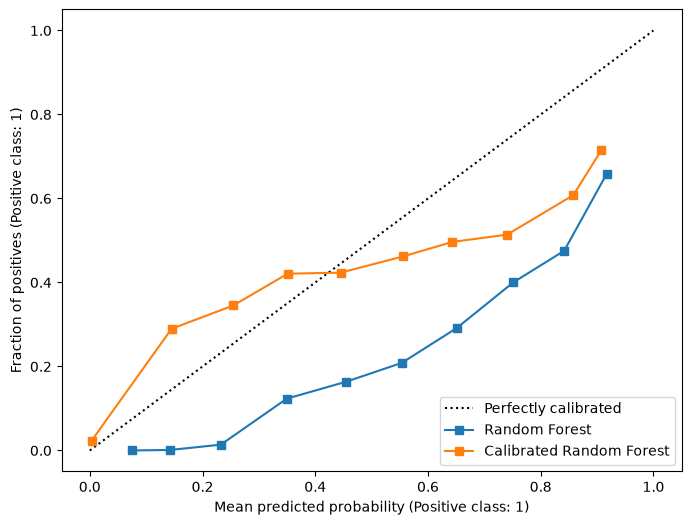

In [63]:
from sklearn.calibration import calibration_curve, CalibrationDisplay
fig, ax = plt.subplots(figsize=(8, 6))

# Базовая модель
CalibrationDisplay.from_estimator(
    best_tree_pipeline,
    X_val,
    y_val,
    n_bins=10,
    strategy='uniform',
    ax=ax,
    name='Random Forest'
)

# Откалиброванная модель
CalibrationDisplay.from_estimator(
    calib_model,
    X_val,
    y_val,
    n_bins=10,
    strategy='uniform',
    ax=ax,
    name='Calibrated Random Forest'
)

In [69]:
brier_score = brier_score_loss(
    y_val,  # истинные метки классов (0 или 1)
    best_tree_pipeline.predict_proba(X_val)[:, 1]   # предсказанные вероятности положительного класса
)
calib_brier_score = brier_score_loss(
    y_val,  # истинные метки классов (0 или 1)
    calib_model.predict_proba(X_val)[:, 1]   # предсказанные вероятности положительного класса
)

delta = brier_score - calib_brier_score
brier_score, calib_brier_score, delta

(0.0985116547740018, 0.05876334952791349, 0.03974830524608831)

По графику видно, что калибровка Random Forest улучшила соответствие предсказанных вероятностей фактической частоте дефолтов. Оценка Бриера также уменьшилась на 0.0397, что говорит об улучшении.

## Поиск порога решения

* Используя откалиброванную модель и калибровочную выборку, найдите порог, при котором будут достигнуты заданные в постановке задачи значения метрик:
    * approval rate — не менее 65%;
    * default rate — не более 2%;
    * missed defaults rate — не более 4%.
    
* Сделайте вывод о достигнутых в этом разделе результатах.

## Анализ матрицы ошибок

* Оцените стабильность модели на тестовых данных. Для этого постройте:
    * матрицу ошибок на калибровочных данных;
    * матрицу классификации на тестовых данных.
* Сделайте вывод о моделях, рассчитав классические метрики машинного обучения и указанные в ТЗ бизнес-метрики.
* Сделайте вывод о стабильности модели.

## Фиксирование итоговой модели

- Опишите лучшую модель и найденный порог классификации.


## Анализ важности признаков

* Проведите анализ важности признаков найденной модели на полных тренировочных данных.
* Используйте `feature_importances_` для найденной модели.
* Сделайте вывод о силе влияния признаков на дефолт.

## Выводы по проекту

Сделайте выводы по проекту. Можете использовать такой план:

1. Цель и задачи исследования.

2. Подготовка данных и выборок.

3. Поиск и настройка модели.

4. Калибровка вероятностей.

5. Оптимизация бизнес-порога.

6. Анализ важности признаков.

7. Финальный пайплайн.

8. Основные выводы и рекомендации для бизнеса.

